# Module 02 · Op-amp (Floyd chương 12)
Notebook tái hiện các phép tính chính; mỗi mục có câu hỏi, mã, và nhận xét dựa trên kết quả thật.

In [1]:
import numpy as np, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline
db = lambda r: 20*np.log10(r)

## 1. CMRR
**Câu hỏi:** Aol = 175 000, Acm = 0,18 thì CMRR bằng bao nhiêu dB? (Floyd Bài 5)

In [2]:
Aol, Acm = 175000, 0.18
CMRR = Aol/Acm
print(f"CMRR = {CMRR:,.0f}  ->  {db(CMRR):.2f} dB")
print(f"250,000 -> {db(250000):.2f} dB   (Floyd Problem 4)")

CMRR = 972,222  ->  119.76 dB
250,000 -> 107.96 dB   (Floyd Problem 4)


**Nhận xét:** CMRR = 972,222 tương ứng 119.76 dB ≈ 120 dB, khớp đáp án sách (120 dB). Nhân thêm 10 lần tỉ số chỉ cộng 20 dB.

## 2. Slew rate và tần số sin tối đa
**Câu hỏi:** Với SR = 0,5 V/μs, sin biên độ đỉnh 10 V có méo ở tần số nào?

f_max = 7.96 kHz


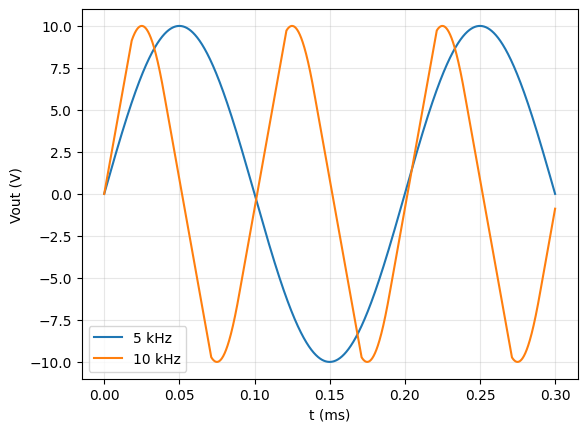

In [3]:
SR = 0.5e6   # V/s
Vp = 10
fmax = SR/(2*np.pi*Vp)
print(f"f_max = {fmax/1e3:.2f} kHz")
t = np.linspace(0, 3/10e3, 3000)
for f in (5e3, 10e3):
    ideal = Vp*np.sin(2*np.pi*f*t); y = np.zeros_like(t)
    for k in range(1, len(t)):
        step = np.clip(ideal[k]-y[k-1], -SR*(t[1]-t[0]), SR*(t[1]-t[0])); y[k] = y[k-1]+step
    plt.plot(t*1e3, y, label=f"{f/1e3:.0f} kHz")
plt.xlabel("t (ms)"); plt.ylabel("Vout (V)"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Nhận xét:** f_max = 7.96 kHz. Đường 5 kHz bám theo sin còn đường 10 kHz bị giới hạn thành dạng tam giác vì đổi mức nhanh hơn slew rate.

## 3. Độ lợi không đảo và đảo
**Câu hỏi:** Tính độ lợi và Vout cho Floyd Bài 13 và bài 15.

In [4]:
Acl = 1 + 560/1.5
print(f"Problem 13: Acl = {Acl:.1f}, Vout = {Acl*10e-3:.3f} V rms")
for lbl, acl, ri, inv in [("a",50,1.0,False),("b",300,10,True),("c",8,12,False),("d",75,2.2,True)]:
    rf = acl*ri if inv else (acl-1)*ri
    print(f"Problem 15({lbl}): Rf = {rf:g} kOhm")

Problem 13: Acl = 374.3, Vout = 3.743 V rms
Problem 15(a): Rf = 49 kOhm
Problem 15(b): Rf = 3000 kOhm
Problem 15(c): Rf = 84 kOhm
Problem 15(d): Rf = 165 kOhm


**Nhận xét:** Acl = 374.3, Vout = 3.743 V rms; bốn giá trị Rf là 49 kΩ, 3000 kΩ, 84 kΩ, 165 kΩ — trùng đáp án sách.

## 4. Trở kháng với hồi tiếp
**Câu hỏi:** Zin và Zout của mạch không đảo thay đổi thế nào?

In [5]:
Aol, Zin, Zout, Rf, Ri = 100000, 2e6, 75, 100e3, 1e3
B = Ri/(Ri+Rf); k = 1 + B*Aol
print(f"B = {B:.5f}, 1+B*Aol = {k:,.1f}")
print(f"Zin(NI) = {k*Zin/1e9:.2f} GOhm,  Zout(NI) = {Zout/k*1e3:.1f} mOhm")

B = 0.00990, 1+B*Aol = 991.1
Zin(NI) = 1.98 GOhm,  Zout(NI) = 75.7 mOhm


**Nhận xét:** 1 + B·Aol ≈ 991.1; Zin từ 2 MΩ lên 1.98 GΩ và Zout từ 75 Ω xuống 75.7 mΩ.

## 5. Đáp ứng tần số vòng hở và vòng kín
**Câu hỏi:** Vẽ Bode biên độ của Aol = 100 dB (fc = 10 Hz) và các độ lợi vòng kín 10, 100, 1000.

Acl=10: fc(cl)=100.0 kHz, Acl*fc(cl)=1.00 MHz
Acl=100: fc(cl)=10.0 kHz, Acl*fc(cl)=1.00 MHz
Acl=1000: fc(cl)=1.0 kHz, Acl*fc(cl)=1.01 MHz


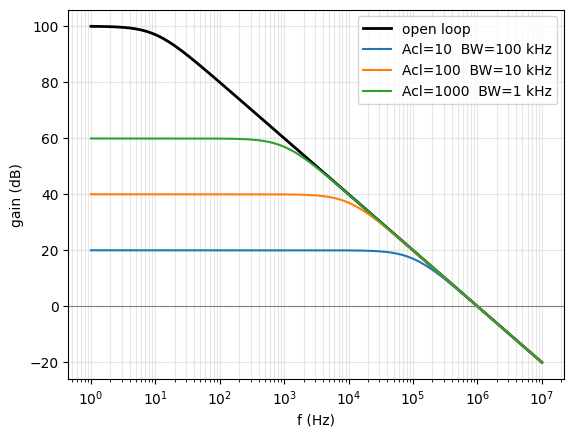

In [6]:
f = np.logspace(0, 7, 600); Aol0, fc = 1e5, 10
Aol = Aol0/np.sqrt(1+(f/fc)**2)
plt.semilogx(f, db(Aol), "k", lw=2, label="open loop")
for acl in (10, 100, 1000):
    B = 1/acl; fcl = fc*(1+B*Aol0)
    A = (Aol0/(1+B*Aol0))/np.sqrt(1+(f/fcl)**2)
    plt.semilogx(f, db(A), label=f"Acl={acl}  BW={fcl/1e3:.0f} kHz")
    print(f"Acl={acl}: fc(cl)={fcl/1e3:.1f} kHz, Acl*fc(cl)={acl*fcl/1e6:.2f} MHz")
plt.axhline(0, color="gray", lw=.8); plt.xlabel("f (Hz)"); plt.ylabel("gain (dB)"); plt.legend(); plt.grid(alpha=.3, which="both"); plt.show()

**Nhận xét:** Tích Acl·fc(cl) xấp xỉ 1 MHz cho cả ba độ lợi (= Aol·fc(ol) = 10⁵ × 10 Hz): tăng độ lợi 10 lần thì băng thông giảm 10 lần.

## 6. Floyd Bài 37–38
**Câu hỏi:** fc(ol) = 750 Hz, Aol = 89 dB, fc(cl) = 5,5 kHz. Tìm Acl (dB) và fT.

In [7]:
Aol = 10**(89/20); k = 5500/750
Acl = Aol/k
print(f"Aol = {Aol:,.0f}; 1+B*Aol = {k:.3f}; Acl = {Acl:,.0f} -> {db(Acl):.1f} dB")
print(f"fT = Acl*fc(cl) = {Acl*5500/1e6:.1f} MHz ; Aol*fc(ol) = {Aol*750/1e6:.1f} MHz")

Aol = 28,184; 1+B*Aol = 7.333; Acl = 3,843 -> 71.7 dB
fT = Acl*fc(cl) = 21.1 MHz ; Aol*fc(ol) = 21.1 MHz


**Nhận xét:** Acl ≈ 3,843 (71.7 dB, sách: 71,7 dB); fT ≈ 21.1 MHz và hai cách tính khớp nhau.

## 7. Mạch trễ RC
**Câu hỏi:** Biên độ và pha của mạch trễ RC theo f/fc.

In [8]:
r = np.array([0.1, 0.5, 1, 2, 10])
for x, a, p in zip(r, 1/np.sqrt(1+r**2), -np.degrees(np.arctan(r))):
    print(f"f/fc={x:>4}: |Vout/Vin|={a:.3f} ({db(a):6.2f} dB), phase={p:6.1f} deg")

f/fc= 0.1: |Vout/Vin|=0.995 ( -0.04 dB), phase=  -5.7 deg
f/fc= 0.5: |Vout/Vin|=0.894 ( -0.97 dB), phase= -26.6 deg
f/fc= 1.0: |Vout/Vin|=0.707 ( -3.01 dB), phase= -45.0 deg
f/fc= 2.0: |Vout/Vin|=0.447 ( -6.99 dB), phase= -63.4 deg
f/fc=10.0: |Vout/Vin|=0.100 (-20.04 dB), phase= -84.3 deg


**Nhận xét:** Tại f = fc biên độ là 0,707 (−3,01 dB) và pha −45°; tại f = 10·fc pha gần −90° và biên độ ≈ 0,0995.

## 8. Sai số do Aol hữu hạn
**Câu hỏi:** Acl thực khác 1/B bao nhiêu?

In [9]:
for Aol in (1e3, 1e4, 1e5, 2e5):
    B = 1/101; A = Aol/(1+B*Aol)
    print(f"Aol={Aol:>9,.0f}: Acl={A:8.3f}  error vs 101 = {(101-A)/101*100:6.3f} %")

Aol=    1,000: Acl=  91.735  error vs 101 =  9.173 %
Aol=   10,000: Acl=  99.990  error vs 101 =  1.000 %
Aol=  100,000: Acl= 100.898  error vs 101 =  0.101 %
Aol=  200,000: Acl= 100.949  error vs 101 =  0.050 %


**Nhận xét:** Với Aol = 10⁵ sai số ≈ 0,1 %; gấp đôi Aol thì sai số giảm còn một nửa — vì vậy Self-Test câu 18 coi độ lợi “vẫn là 25”.